### Analysing branches of the trajectory

<div class="alert alert-block alert-info">
<b>PILOT</b>

A trajectory can have several parts or branches, e.g. one branch towards a disease sub-type and another one towards a different sub-type, or a healthy part and a disease part. The cell types that change can be different in each branch. In this tutorial we show how to split the trajectory by choosing nodes of the principal graph, and how to run the cell type importance (and the rest of the analysis) for each branch separately.

We use two examples: first the Myocardial Infarction data (a healthy part and a disease part), then, at the end, a lung cancer atlas with two disease branches that start from the normal samples (normal to COPD and normal to lung adenocarcinoma), together with the clinical variables of each branch. For the Myocardial Infarction data, you can download the Anndata (h5ad) file from [here](https://costalab.ukaachen.de/open_data/PILOT/myocardial_infarction.h5ad), and place it in the _Datasets_ folder. The first steps are the same as in the [Myocardial Infarction tutorial](https://pilot.readthedocs.io/en/latest/Myocardial_infarction.html).
</div>

In [ ]:
import pilotpy as pl
import scanpy as sc
import matplotlib.pyplot as plt

##### Reading Anndata

In [ ]:
adata = sc.read_h5ad('Datasets/myocardial_infarction.h5ad')

##### Wasserstein distance and trajectory:
<div class="alert alert-block alert-info">
We compute the Wasserstein distances between the samples and the trajectory, as in the Myocardial Infarction tutorial.
</div>

In [ ]:
pl.tl.wasserstein_distance(
    adata,
    emb_matrix = 'PCA',
    clusters_col = 'cell_subtype',
    sample_col = 'sampleID',
    status = 'Status',
    )

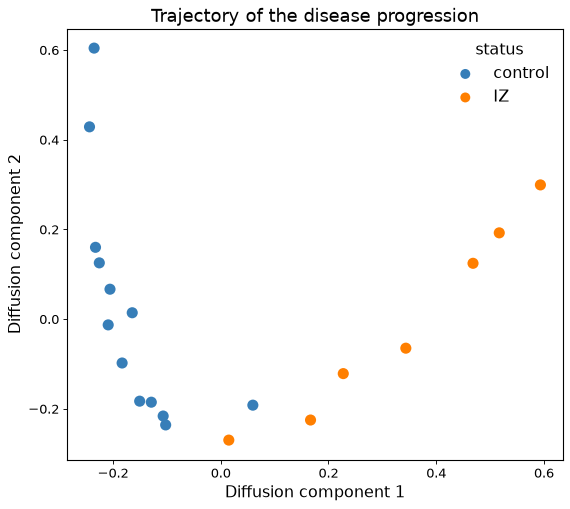

In [ ]:
pl.pl.trajectory(adata)

##### Principal graph and its nodes:
<div class="alert alert-block alert-info">
PILOT fits a principal graph (a tree) through the samples and orders them along it, starting from the root (red star). The numbers in the plot are the node numbers. We use them to choose the branches.

Note: the node numbers can change when the graph is fitted again (e.g. in a new Python session or with other settings), so always look at your own plot before choosing the nodes.
</div>

Root of the trajectory: node 6 (end node where the control samples come first).

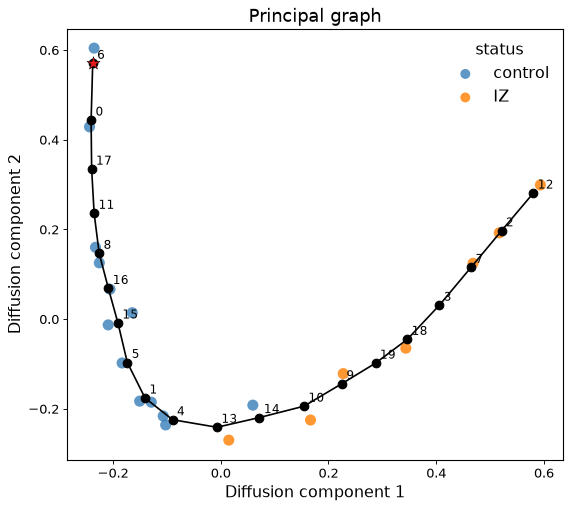

In [ ]:
pl.pl.fit_pricipla_graph(adata, source_node = 'auto', root_status = 'control')

##### Which samples belong to which node:
<div class="alert alert-block alert-info">
Each sample belongs to its nearest node of the graph. `pl.tl.sample_nodes` shows the node, the status and the pseudotime of every sample, which helps to choose the nodes of a branch.
</div>

In [ ]:
pl.tl.sample_nodes(adata)

,sampleID,node,status,pseudotime
0,RZ_P9,0,control,0.141687
1,control_P8,1,control,0.759073
2,RZ_BZ_P12,1,control,0.773940
3,IZ_P16,2,IZ,1.617639
4,RZ_FZ_P5,4,control,0.811143
5,control_P1,4,control,0.828181
6,RZ_P6,5,control,0.672575
7,control_P7,6,control,0.000000
8,GT_IZ_P13,7,IZ,1.534083
9,RZ_P11,8,control,0.410313


##### Branch 1, the healthy part:
<div class="alert alert-block alert-info">
`pl.tl.select_branch` keeps only the samples of the given nodes. All other samples are ignored in the next steps, so you can also use it to leave out samples you do not want to analyse. Parameters:

- `nodes`: the node numbers of the branch (any order), here [6, 0, 17, 11, 8, 16, 15, 5, 1, 4]: from the root to the end of the control samples.
- `name`: the name of the branch, used in the plot titles and in the names of the result folders.

The Wasserstein distances, the trajectory and the graph are not changed. `pl.pl.principal_graph` now shows the branch in orange; the other samples are faded.
</div>

Branch 'healthy part': 12 of 20 samples (control: 12, IZ: 0).

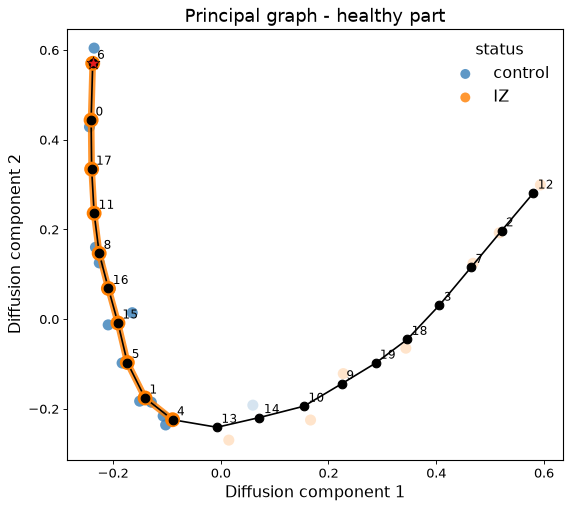

In [ ]:
pl.tl.select_branch(adata, nodes = [6, 0, 17, 11, 8, 16, 15, 5, 1, 4], name = 'healthy part')
pl.pl.principal_graph(adata)

##### Cell type importance of the healthy part:
<div class="alert alert-block alert-info">
The next steps work as usual, but only use the samples of the branch, ordered along the trajectory. The results are saved in sub-folders named after the branch (e.g. 'Results_PILOT/plots/Cell_type_Report/branch_healthy_part').
</div>

In [ ]:
pl.tl.cell_importance_calculation(adata)

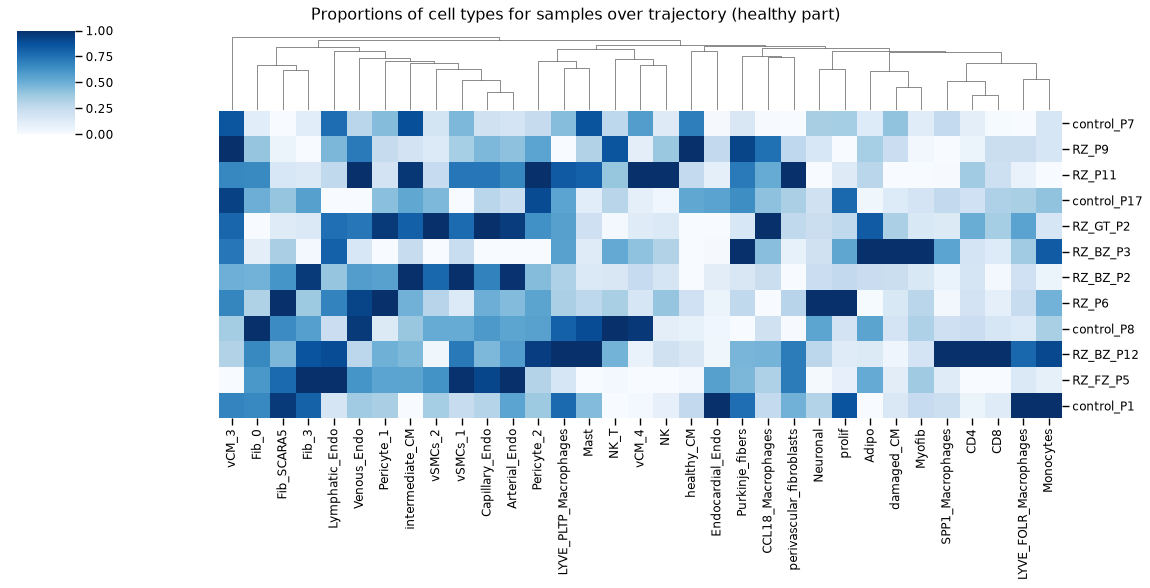

In [ ]:
pl.pl.heatmap_proportions(adata)

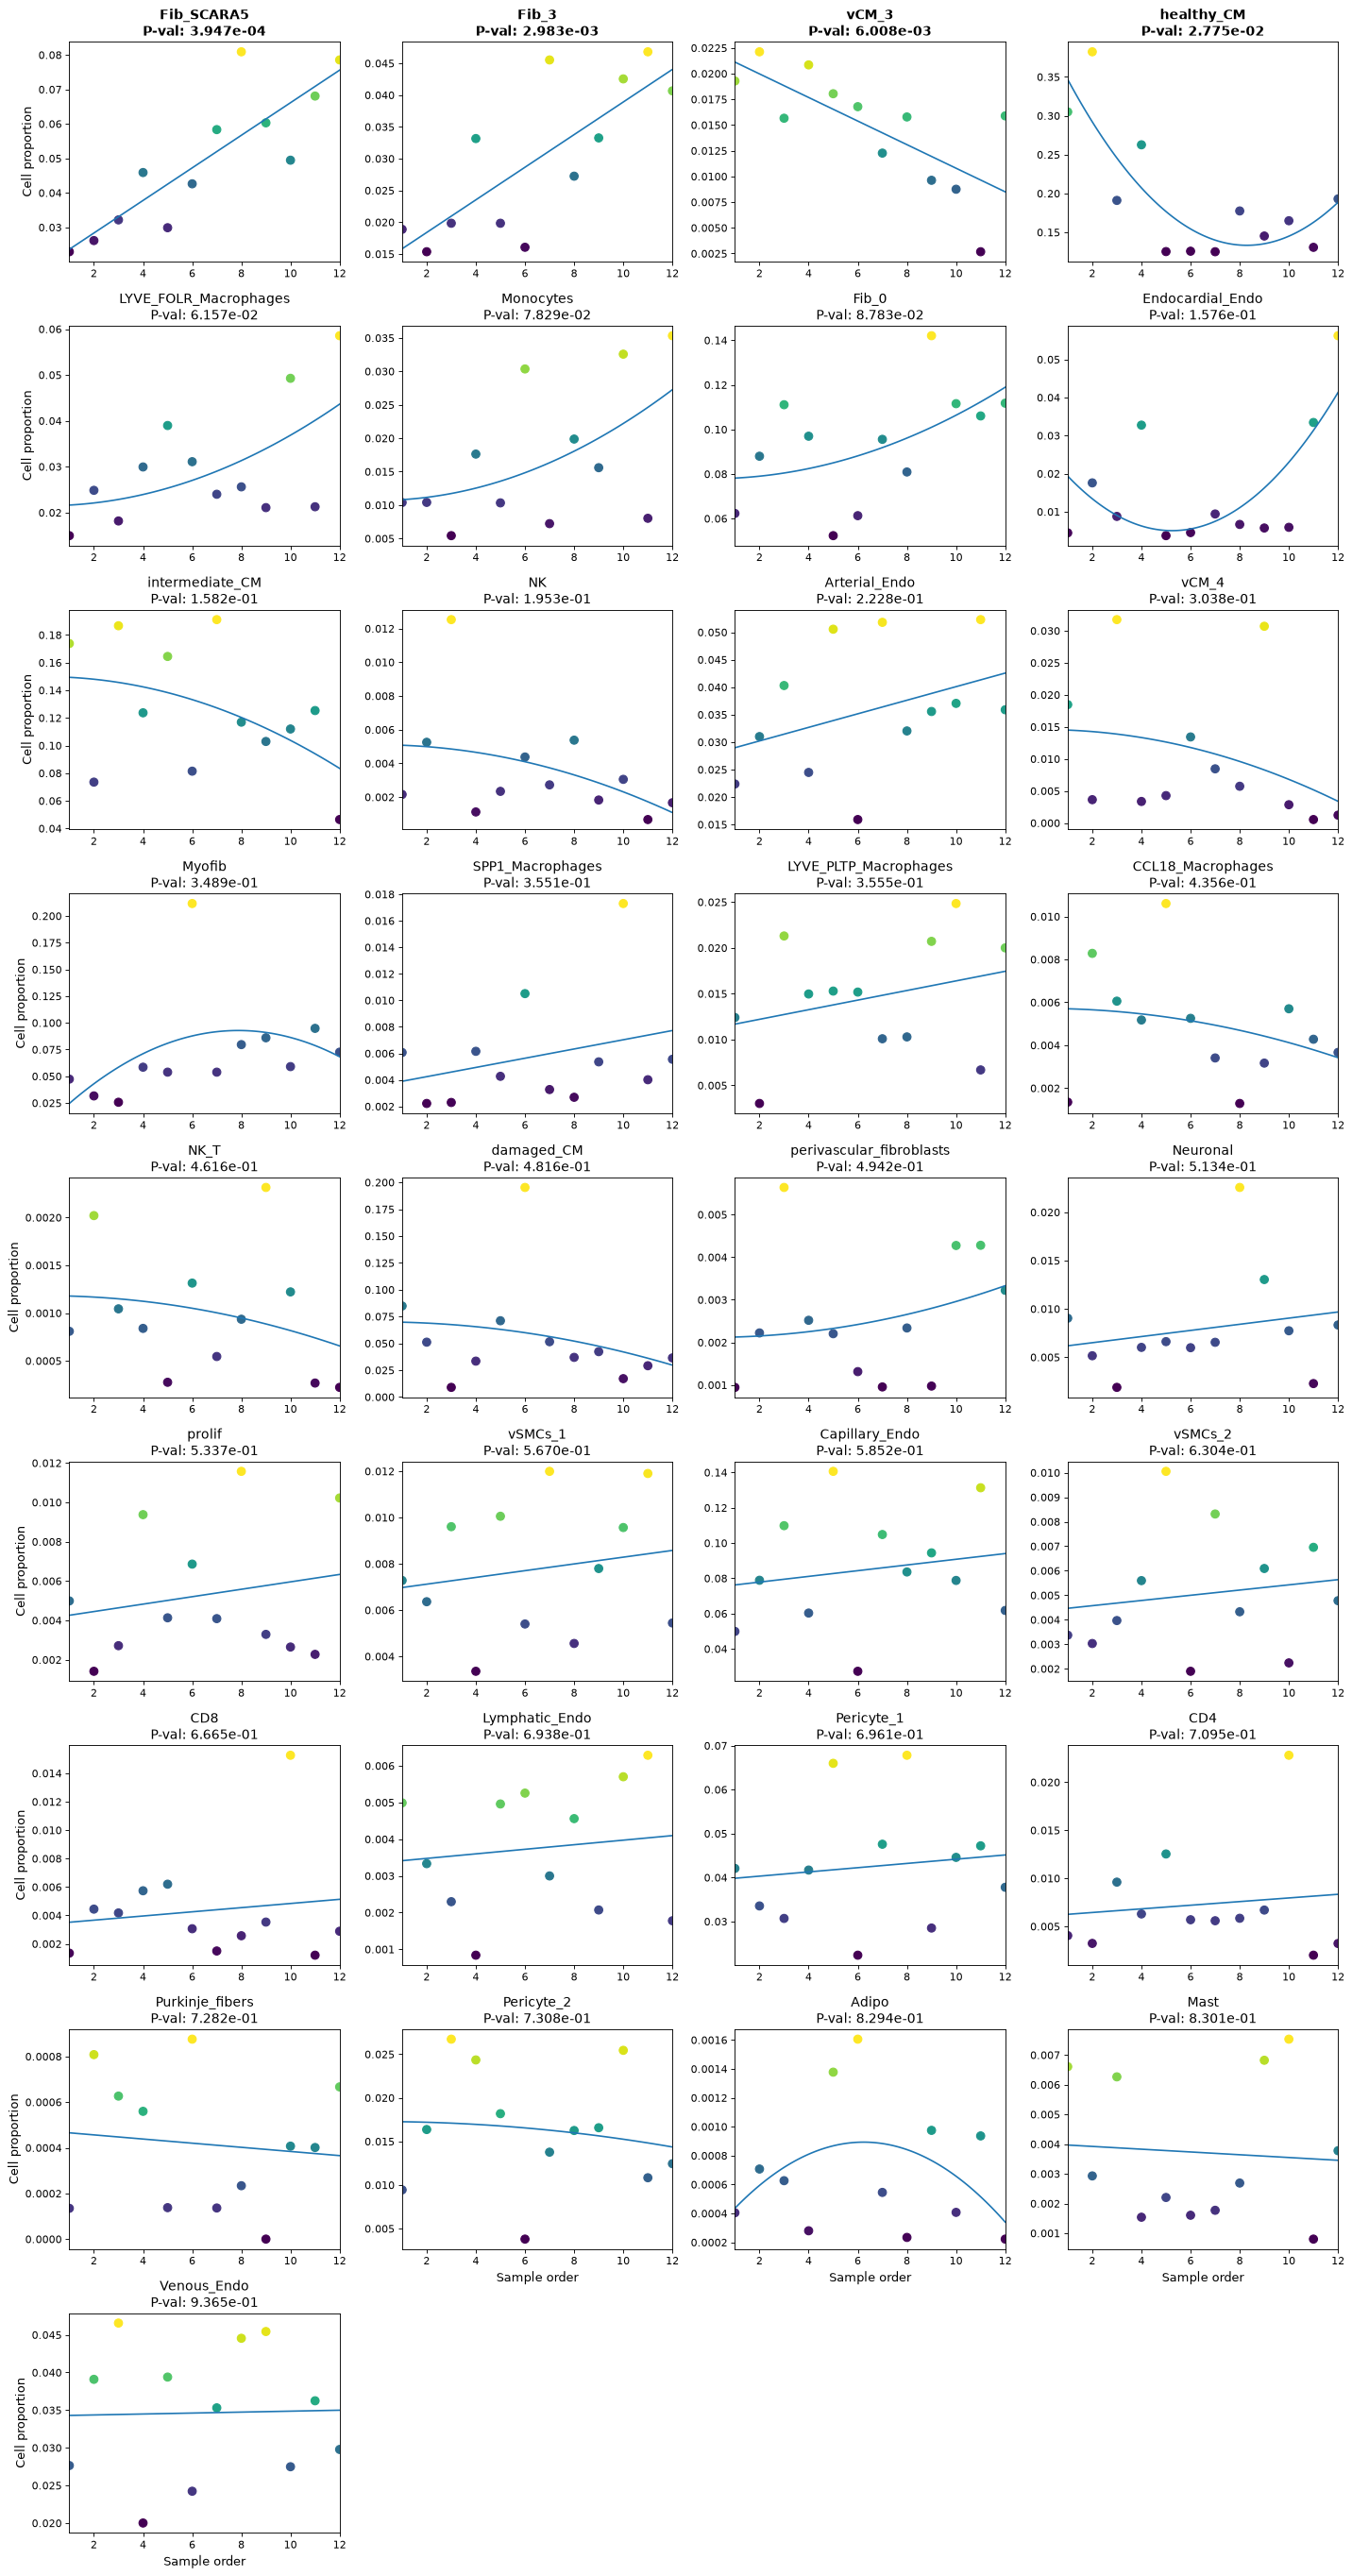

In [ ]:
pl.pl.cell_importance_grid(adata)

##### Branch 2, the disease part:
<div class="alert alert-block alert-info">
Now we choose the second branch, here the nodes [1, 4, 13, 14, 10, 9, 19, 18, 3, 7, 2, 12]: from the end of the healthy part to the end of the trajectory. We repeat the analysis. Nodes can be part of both branches (here the last two nodes of the healthy part).
</div>

Branch 'disease part': 12 of 20 samples (IZ: 7, control: 5).

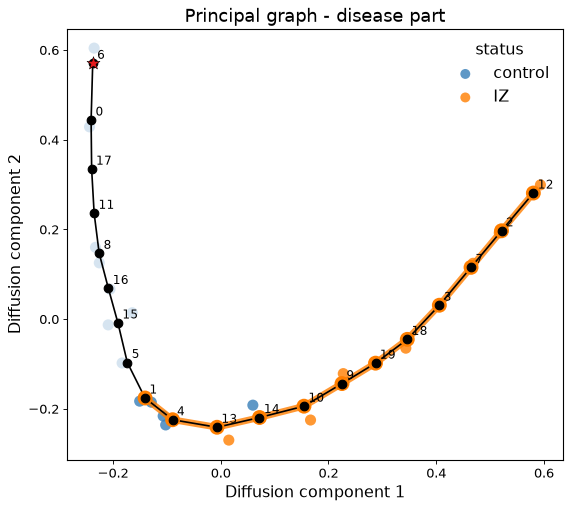

In [ ]:
pl.tl.select_branch(adata, nodes = [1, 4, 13, 14, 10, 9, 19, 18, 3, 7, 2, 12], name = 'disease part')
pl.pl.principal_graph(adata)

In [ ]:
pl.tl.cell_importance_calculation(adata)

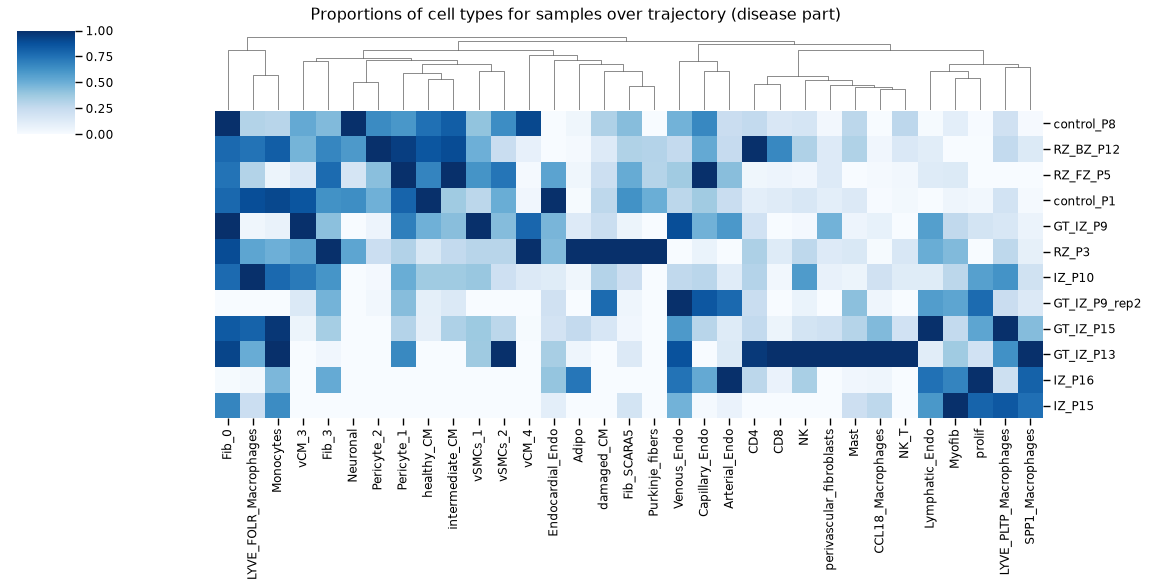

In [ ]:
pl.pl.heatmap_proportions(adata)

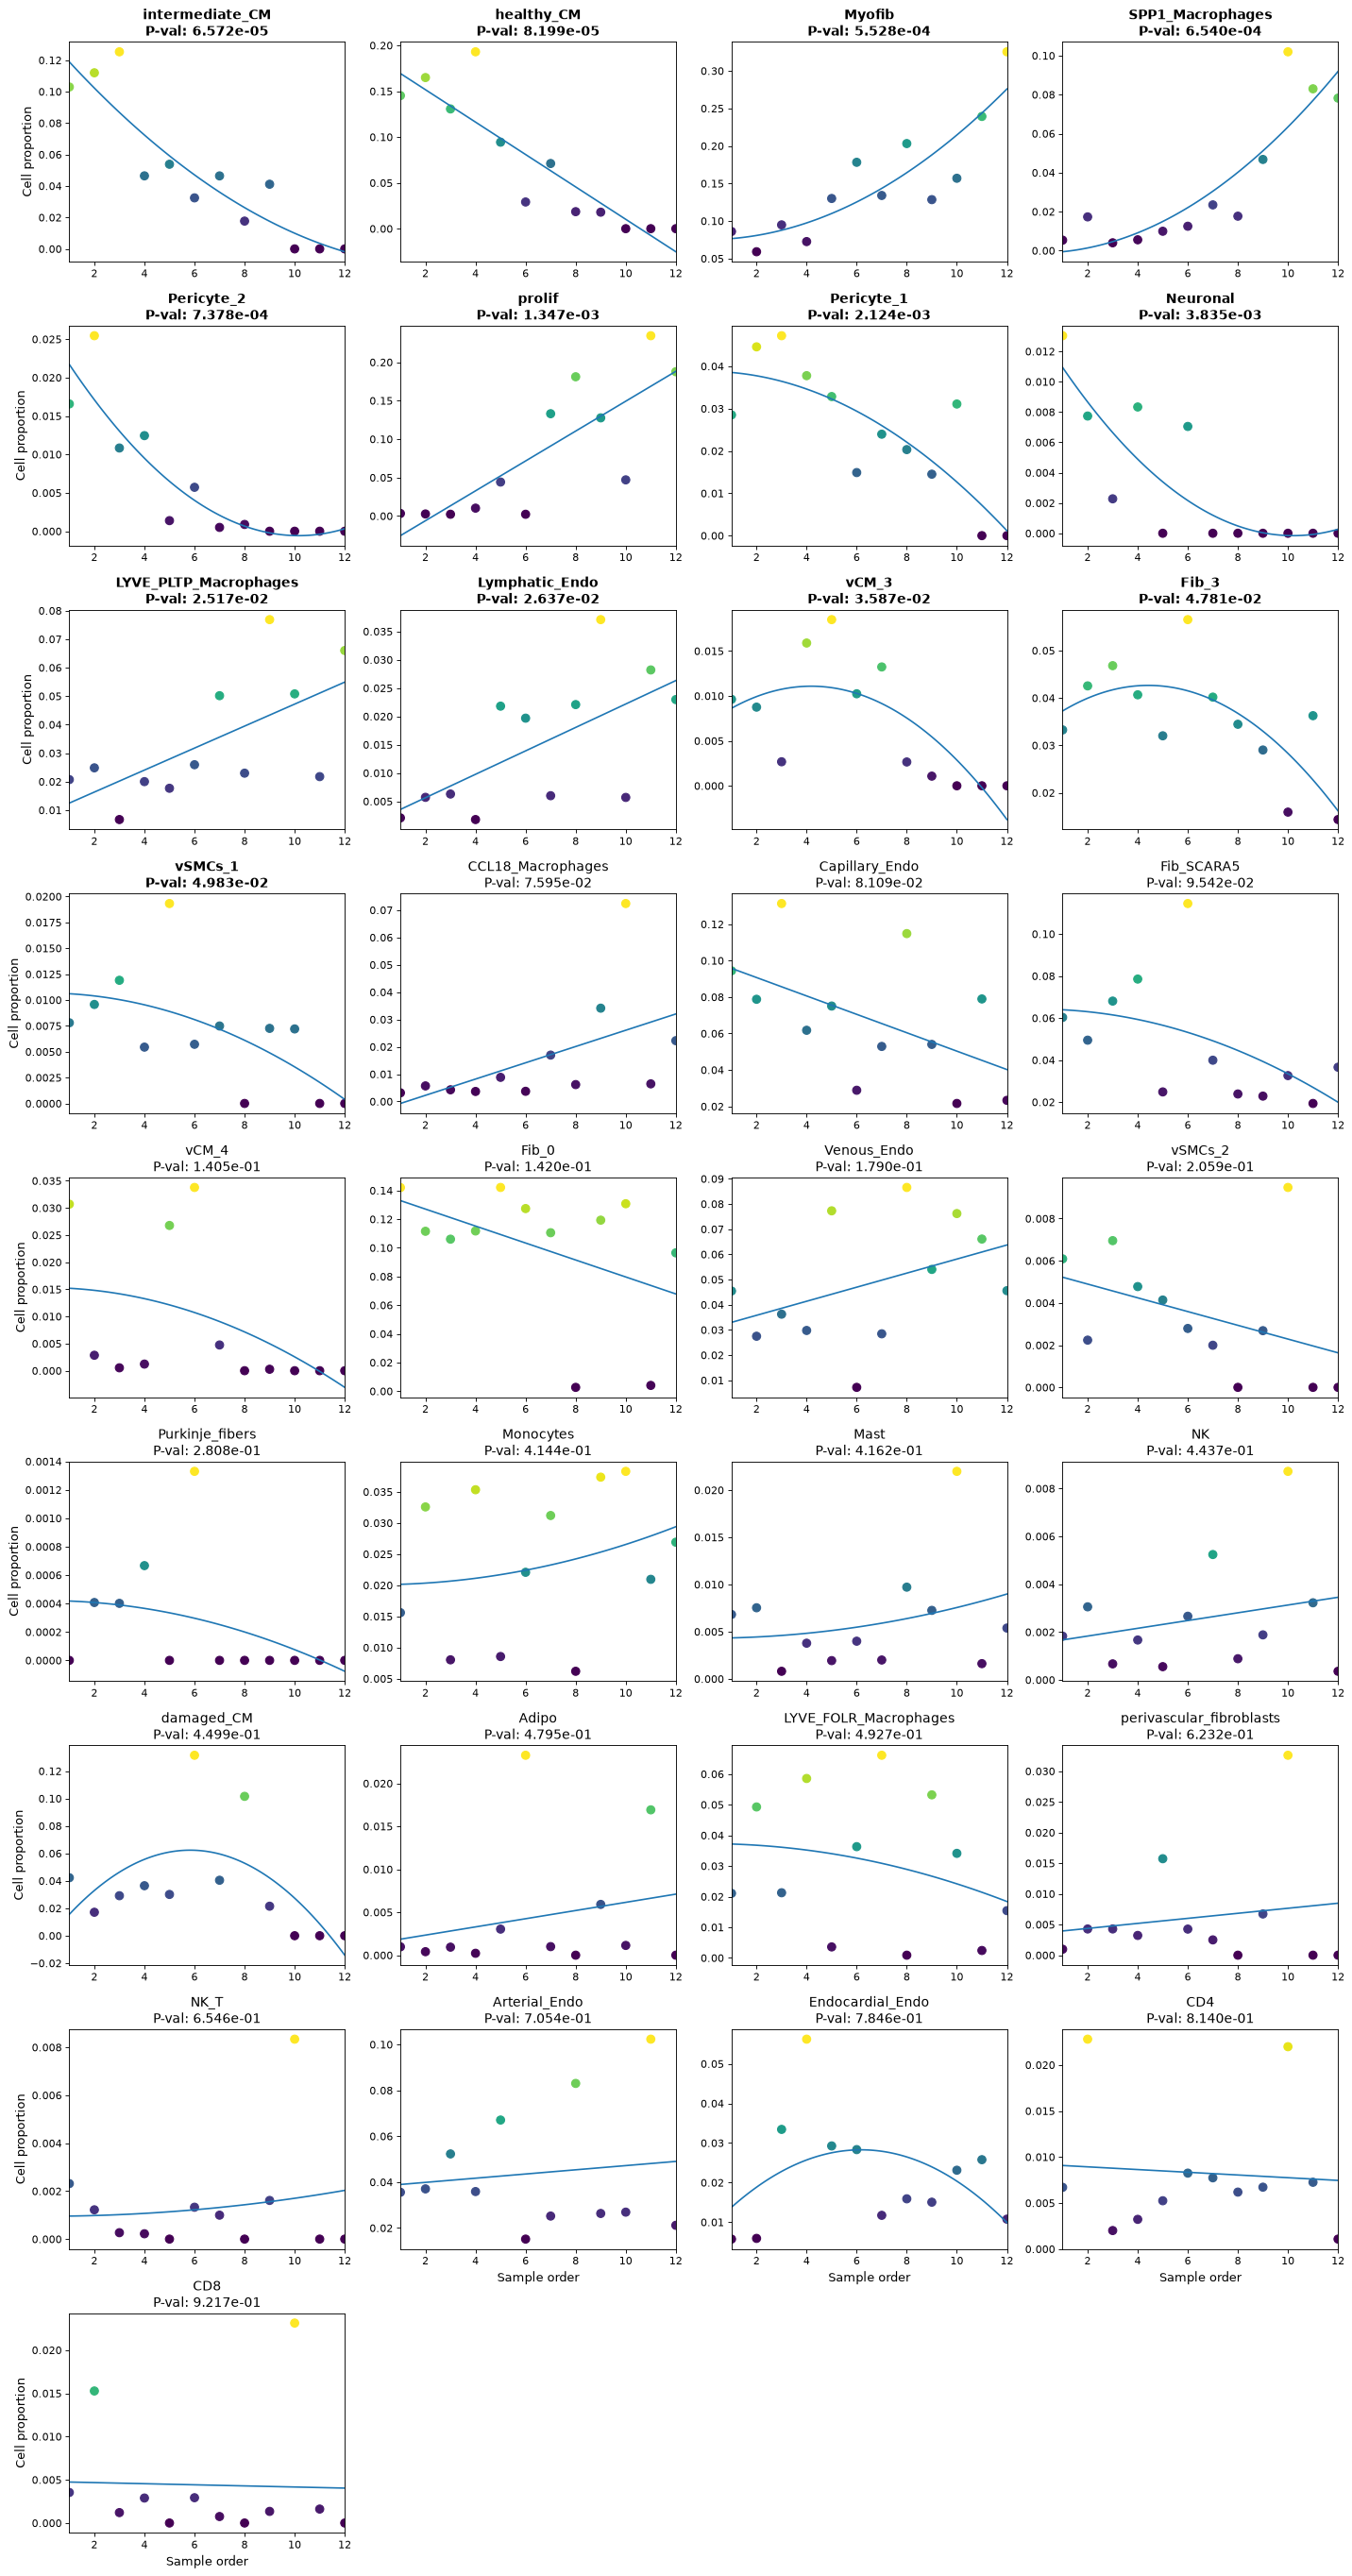

In [ ]:
pl.pl.cell_importance_grid(adata)

##### Both branches side by side:
<div class="alert alert-block alert-info">
With `ax`, the principal graphs of the branches can be drawn next to each other.
</div>

Branch 'healthy part': 12 of 20 samples (control: 12, IZ: 0).
Branch 'disease part': 12 of 20 samples (IZ: 7, control: 5).

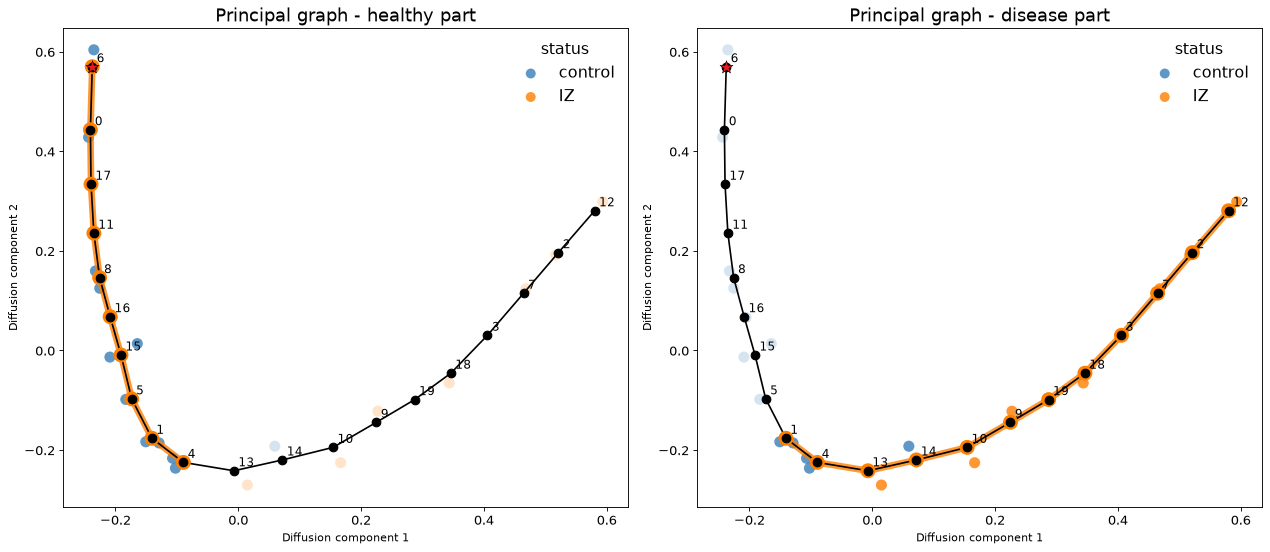

In [ ]:
fig, axes = plt.subplots(1, 2, figsize = (16, 7))
pl.tl.select_branch(adata, nodes = [6, 0, 17, 11, 8, 16, 15, 5, 1, 4], name = 'healthy part')
pl.pl.principal_graph(adata, ax = axes[0])
pl.tl.select_branch(adata, nodes = [1, 4, 13, 14, 10, 9, 19, 18, 3, 7, 2, 12], name = 'disease part')
pl.pl.principal_graph(adata, ax = axes[1])
plt.tight_layout()
plt.show()

##### Back to all samples:
<div class="alert alert-block alert-info">
`nodes = None` removes the selection, so all samples are used again (for example before the gene analysis of the Myocardial Infarction tutorial).
</div>

In [ ]:
pl.tl.select_branch(adata, nodes = None)
pl.tl.cell_importance_calculation(adata)

No branch selected: all samples are used.

##### Summary:
<div class="alert alert-block alert-info">
Splitting the trajectory shows which cell types change in which part of the disease progression. In this data, only a few cell types change in the healthy part, while in the disease part the healthy cardiomyocytes (`healthy_CM`) decrease and myofibroblasts (`Myofib`), `SPP1_Macrophages` and proliferating cells (`prolif`) increase.

The same works for any trajectory: look at the principal graph, choose the nodes of each branch (or leave out the nodes of samples you do not want to analyse), and run the analysis for each branch.
</div>

### Second example: lung cancer atlas

<div class="alert alert-block alert-info">
<b>Lung cancer atlas</b>

The second example is the lung cancer single-cell atlas (Salcher et al., 2022; data described in [Zenodo 15575593](https://zenodo.org/records/15575593), atlas in [Zenodo 7227571](https://zenodo.org/records/7227571)). We use the lung tissue samples measured with 10x: 941,504 cells of 165 donors (51 normal, 18 chronic obstructive pulmonary disease (COPD), 71 lung adenocarcinoma, 12 squamous cell lung carcinoma, 13 non-small cell lung carcinoma), in 12 cell types (`ann_coarse`).

Here the trajectory does not go in one direction: one branch goes from the normal samples towards COPD and another one towards lung adenocarcinoma. We analyse both branches, and we use the clinical variables (2.1.2) to see which variables, and which batch, follow each branch.

Download the data from the links above and place it in `Datasets/` (here as `lung_atlas.h5ad`).
</div>

In [ ]:
import pandas as pd

adata_lung = sc.read_h5ad('Datasets/lung_atlas.h5ad')

##### Wasserstein distance:
<div class="alert alert-block alert-info">
The data comes from 11 studies, so we use the batch-corrected scVI embedding of the atlas (`X_scVI`) instead of the PCA. The samples are the donors (`donor_id`), the status is the disease.
</div>

In [ ]:
pl.tl.wasserstein_distance(
    adata_lung,
    emb_matrix = 'X_scVI',
    clusters_col = 'ann_coarse',
    sample_col = 'donor_id',
    status = 'disease',
    )

##### Trajectory:
<div class="alert alert-block alert-info">
With many samples, `n_neighbors` (the number of neighbor samples used for the trajectory, default 64) changes the shape. With 32 neighbors the three groups are separated: lung adenocarcinoma on the left, normal and COPD samples on the right, and a third arm on top.
</div>

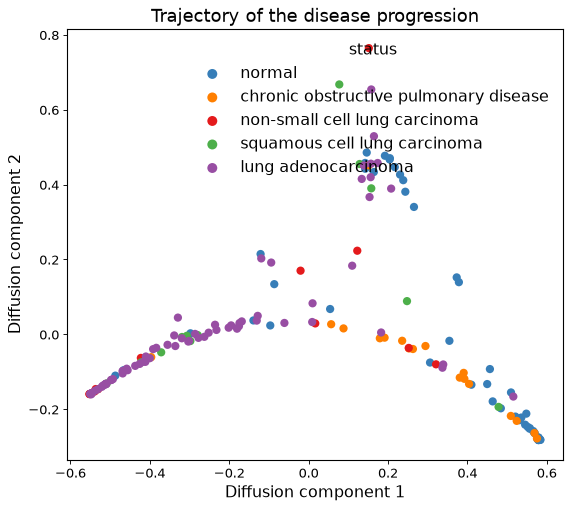

In [ ]:
pl.pl.trajectory(adata_lung, n_neighbors = 32)

##### Batch on the trajectory:
<div class="alert alert-block alert-info">
Before we interpret the branches, we check the batch. `pl.pl.trajectory_variable` colors the samples by any column, here the study. All COPD samples and 28 of the 51 normal samples come from one study (Adams_Kaminski_2020); they form the right arm. So the difference between this arm and the rest is partly a study (batch) effect. Many normal samples of the other studies are in the top arm, together with tumor samples of the same studies.
</div>

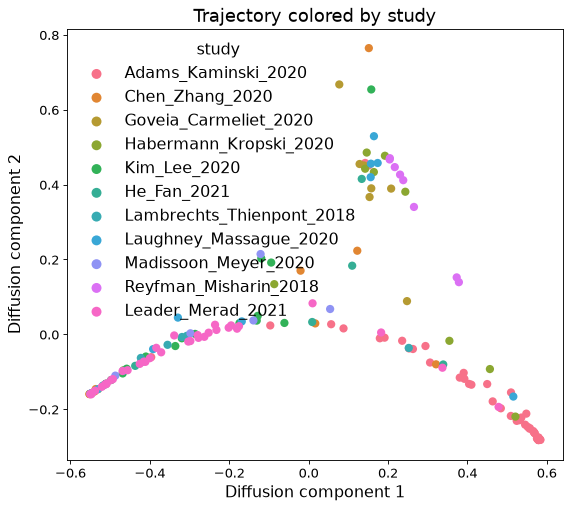

In [ ]:
pl.pl.trajectory_variable(adata_lung, 'study', show_graph = False)

##### Principal graph:
<div class="alert alert-block alert-info">
The root is the end node with the most normal samples. The numbers are the node numbers; we use them for the branches (look at your own plot, the numbers can change between sessions).
</div>

Root of the trajectory: node 1 (end node where the control samples come first).

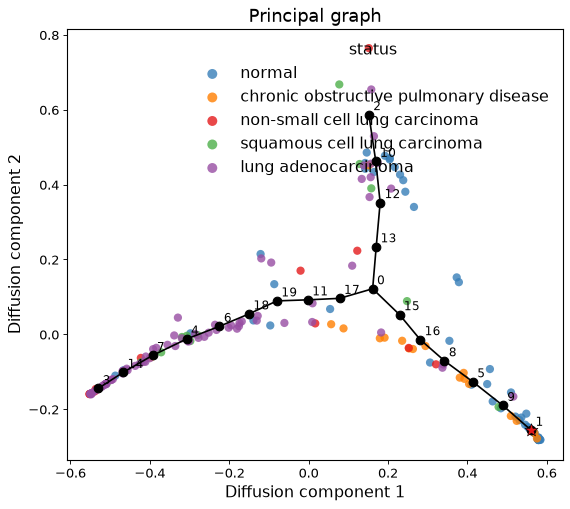

In [ ]:
pl.pl.fit_pricipla_graph(adata_lung, source_node = 'auto', root_status = 'normal')

In [ ]:
nodes = pl.tl.sample_nodes(adata_lung)
pd.crosstab(nodes['node'], nodes['status'])

status,chronic obstructive pulmonary disease,lung adenocarcinoma,squamous cell lung carcinoma,non-small cell lung carcinoma,normal
node,,,,,
1,3,0,0,0,20
2,0,2,1,1,0
3,0,15,1,6,0
4,0,9,4,0,1
5,4,0,0,0,3
6,0,6,0,0,0
7,1,8,2,1,0
8,0,2,0,1,2
9,1,1,1,0,4


##### Clinical variables on the whole trajectory:
<div class="alert alert-block alert-info">
`pl.tl.correlation_with_trajectory` tests all sample variables at once (see the [Kidney tutorial](https://pilot.readthedocs.io/en/latest/Kidney_trajectory.html)). The study comes first: the trajectory is strongly linked to the batch, as the plot above shows.
</div>

In [ ]:
pl.tl.cell_importance_calculation(adata_lung)
res = pl.tl.correlation_with_trajectory(adata_lung)
res.head(10)

Tested 17 variables (12 categorical, 5 numeric); skipped 34 columns.
  skipped (differs between the cells of a sample (cell-level)): ann_fine, cell_type_predicted, leiden, ann_coarse, cell_type_tumor, cell_type_major, cell_type_neutro, cell_type_neutro_coarse, ...
  skipped (only one value): doublet_status, platform, suspension_type, organism, tissue, organism_ontology_term_id, tissue_ontology_term_id
  skipped (same groups as 'assay'): assay_ontology_term_id
  skipped (same groups as 'development_stage'): development_stage_ontology_term_id
  skipped (same groups as 'disease'): accLabel, disease_ontology_term_id
  skipped (same groups as 'sex'): sex_ontology_term_id
  skipped (too many different values (165 for 165 samples, e.g. an ID)): sample, accSample
  skipped (too many missing values (146 of 165)): EGFR_mutation, TP53_mutation, ALK_mutation, BRAF_mutation, ERBB2_mutation, KRAS_mutation, ROS_mutation
  skipped (too many missing values (165 of 165)): self_reported_ethnicity, self_r

,Feature,Type,Level,Test,Statistic,P_value,Adjusted_P_value,Kruskal_P_value,N_samples,N_groups,Note
0,study,categorical,sample,ANOVA,21.118918,2.578121e-24,4.382805e-23,5.841455e-16,165,11,
1,dataset,categorical,sample (most frequent),ANOVA,14.563837,5.533410e-23,4.703398e-22,3.542170e-14,164,17,1 group(s) with < 2 samples not tested
2,origin,categorical,sample (most frequent),ANOVA,45.644463,2.111309e-21,1.196409e-20,3.009417e-16,165,4,
3,tumor_stage,categorical,sample,ANOVA,63.220490,5.448963e-21,2.315809e-20,2.512663e-16,164,3,
4,disease,categorical,sample,ANOVA,32.245659,1.058288e-19,3.598179e-19,4.789446e-15,165,5,
5,uicc_stage,categorical,sample,ANOVA,31.564839,2.388143e-19,6.766405e-19,7.487959e-15,164,5,
6,origin_fine,categorical,sample (most frequent),ANOVA,17.112955,7.580832e-13,1.841059e-12,6.453232e-10,130,6,
7,n_genes_by_counts,numeric,cell (mean),Spearman,-0.498926,9.070189e-12,1.927415e-11,NaN,165,165,
8,age,numeric,sample,Spearman,0.472102,1.140865e-07,2.154966e-07,NaN,114,48,
9,pct_counts_mito,numeric,cell (mean),Spearman,0.360428,1.980500e-06,3.366850e-06,NaN,165,36,


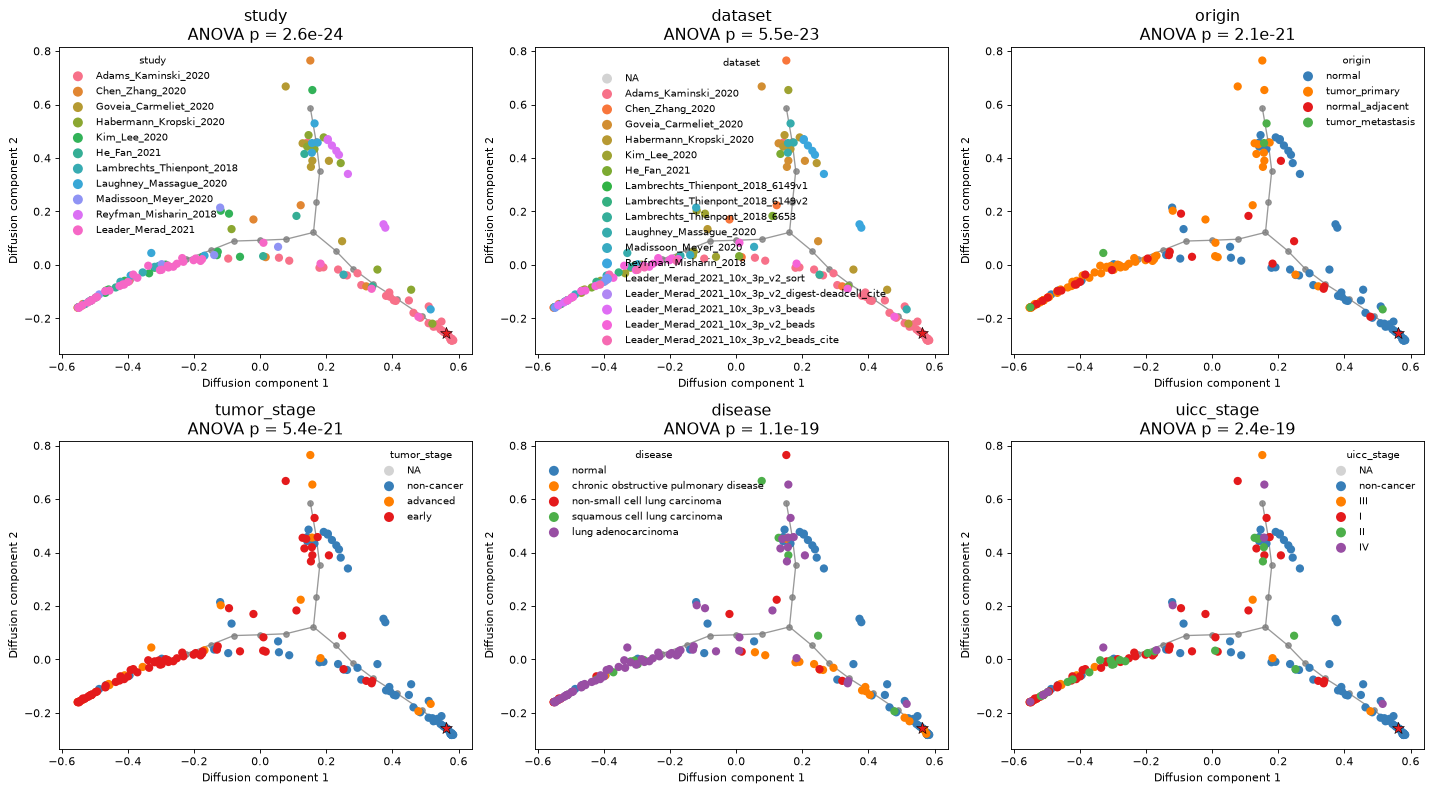

In [ ]:
pl.pl.trajectory_associations(adata_lung, top = 6)

##### Branch 1, normal to COPD:
<div class="alert alert-block alert-info">
The nodes [1, 9, 5, 8, 16, 15]: from the root (normal) along the right arm to the COPD samples. Along this branch the macrophages/monocytes decrease, while T cells, NK cells, plasma cells and mast cells increase.
</div>

Branch 'normal to COPD': 53 of 165 samples (normal: 31, chronic obstructive pulmonary disease: 14, lung adenocarcinoma: 4, squamous cell lung carcinoma: 2, non-small cell lung carcinoma: 2).

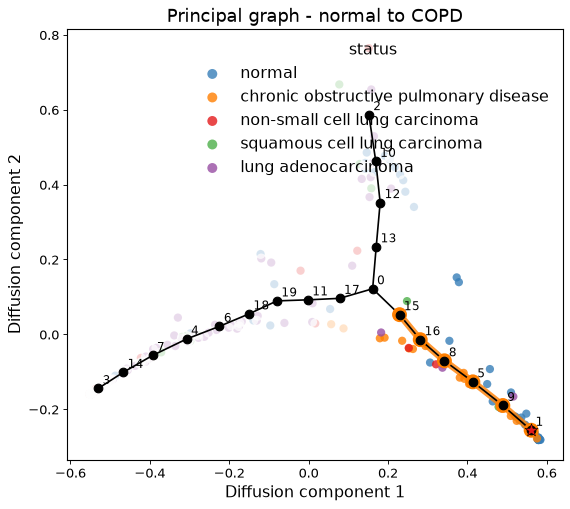

In [ ]:
pl.tl.select_branch(adata_lung, nodes = [1, 9, 5, 8, 16, 15], name = 'normal to COPD')
pl.pl.principal_graph(adata_lung)

In [ ]:
pl.tl.cell_importance_calculation(adata_lung)

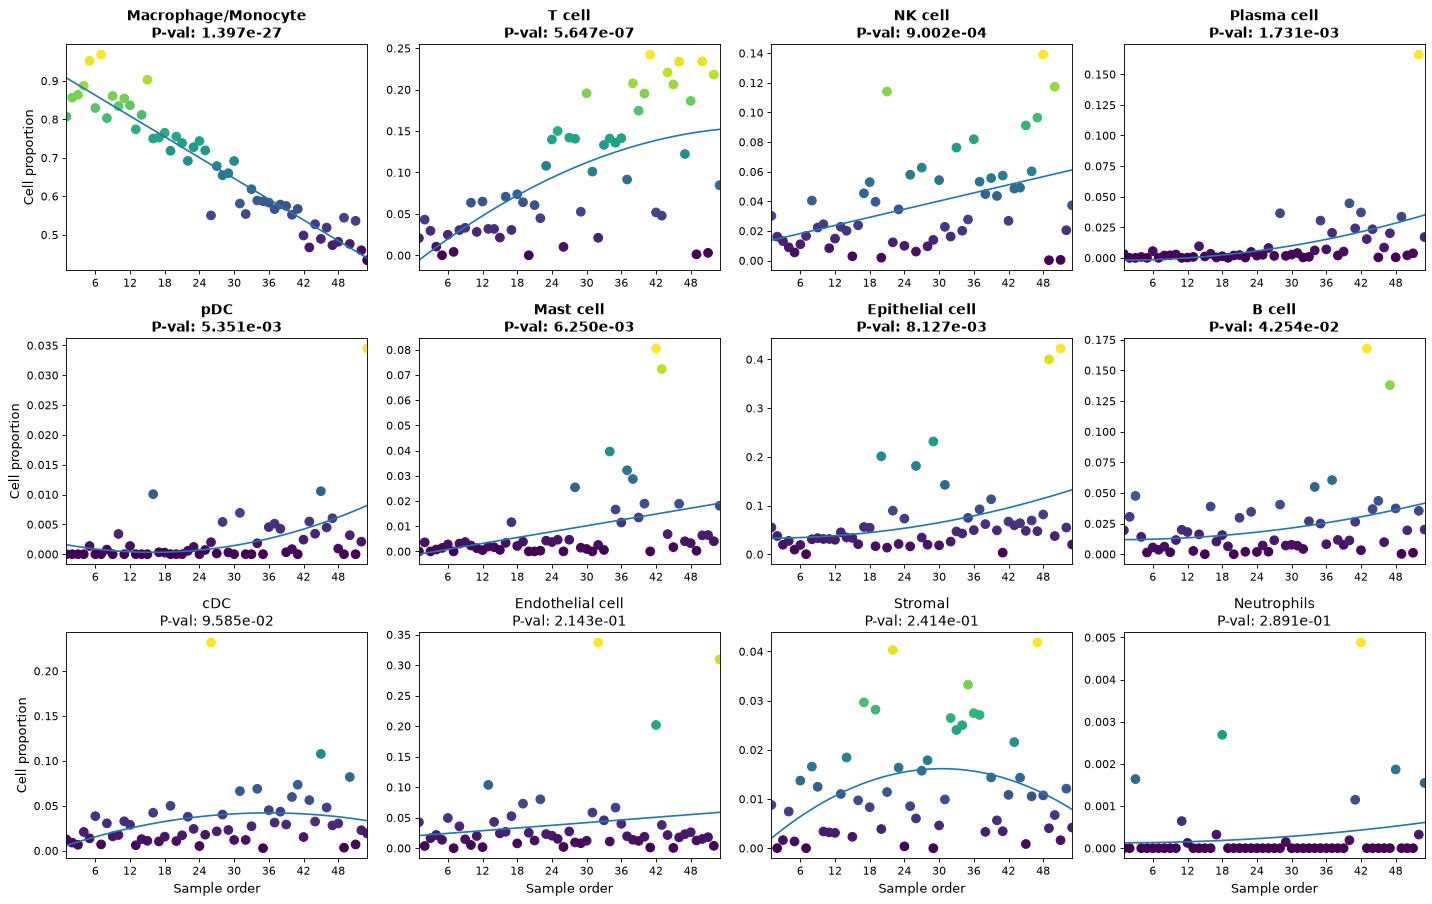

In [ ]:
pl.pl.cell_importance_grid(adata_lung)

##### Clinical variables of branch 1:
<div class="alert alert-block alert-info">
The same tests, now only with the samples of the branch. Besides the disease, smoking (`ever_smoker`) follows this branch: COPD is mainly caused by smoking. The study is skipped here because it has the same groups as `dataset`.
</div>

In [ ]:
res_copd = pl.tl.correlation_with_trajectory(adata_lung)
res_copd.head(10)

Tested 13 variables (10 categorical, 3 numeric); skipped 38 columns.
  skipped (differs between the cells of a sample (cell-level)): ann_fine, cell_type_predicted, leiden, ann_coarse, cell_type_tumor, cell_type_major, cell_type_neutro, cell_type_neutro_coarse, ...
  skipped (fewer than 2 groups with >= 2 samples): total_counts_mito, pct_counts_mito
  skipped (only one value): doublet_status, platform, suspension_type, organism, tissue, organism_ontology_term_id, tissue_ontology_term_id
  skipped (same groups as 'assay'): assay_ontology_term_id
  skipped (same groups as 'dataset'): study
  skipped (same groups as 'disease'): accLabel, disease_ontology_term_id
  skipped (same groups as 'sex'): sex_ontology_term_id
  skipped (too many different values (32 for 48 samples, e.g. an ID)): development_stage, development_stage_ontology_term_id
  skipped (too many different values (53 for 53 samples, e.g. an ID)): sample, accSample
  skipped (too many missing values (51 of 53)): EGFR_mutation, T

,Feature,Type,Level,Test,Statistic,P_value,Adjusted_P_value,Kruskal_P_value,N_samples,N_groups,Note
0,disease,categorical,sample,ANOVA,5.122053,0.001613,0.020974,0.003677,53,5,
1,ever_smoker,categorical,sample,ANOVA,8.099187,0.006543,0.042528,0.008793,49,2,
2,origin,categorical,sample (most frequent),ANOVA,4.396237,0.017537,0.046094,0.021217,52,3,1 group(s) with < 2 samples not tested
3,dataset,categorical,sample (most frequent),ANOVA,3.740497,0.017690,0.046094,0.025798,48,4,5 group(s) with < 2 samples not tested
4,origin_fine,categorical,sample (most frequent),ANOVA,5.811754,0.019972,0.046094,0.025347,48,2,2 group(s) with < 2 samples not tested
5,tumor_stage,categorical,sample,ANOVA,4.162573,0.021274,0.046094,0.024449,53,3,
6,uicc_stage,categorical,sample,ANOVA,3.135819,0.033892,0.062941,0.039493,52,4,1 group(s) with < 2 samples not tested
7,age,numeric,sample,Spearman,0.283207,0.051113,0.083058,NaN,48,32,
8,is_primary_data,categorical,sample,ANOVA,3.154673,0.081676,0.117976,0.081781,53,2,
9,sex,categorical,sample,ANOVA,2.633029,0.110951,0.144236,0.110280,52,2,


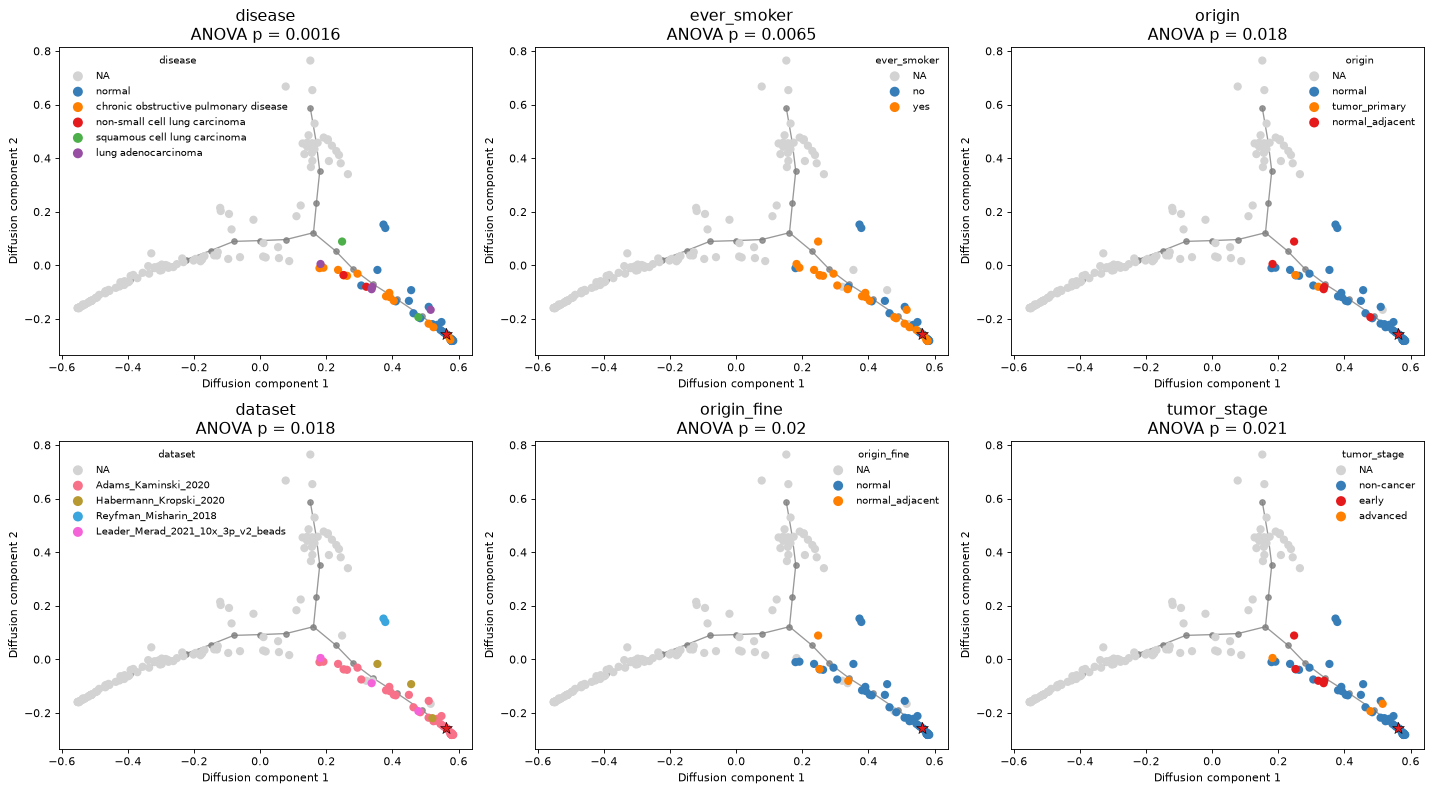

In [ ]:
pl.pl.trajectory_associations(adata_lung, top = 6)

##### Branch 2, normal to lung adenocarcinoma:
<div class="alert alert-block alert-info">
The nodes [1, 0, 17, 11, 19, 18, 6, 4, 7, 14, 3]: the normal samples at the root, then the centre of the graph and the left arm to the lung adenocarcinoma samples. The COPD nodes are left out, so the branch goes directly from normal to cancer. Here the T cells increase strongly and the macrophages/monocytes decrease; the B cells also increase. In the clinical variables, the tumor stage comes first, but the study is still strongly linked.
</div>

Branch 'normal to adenocarcinoma': 107 of 165 samples (lung adenocarcinoma: 57, normal: 28, non-small cell lung carcinoma: 9, squamous cell lung carcinoma: 7, chronic obstructive pulmonary disease: 6).

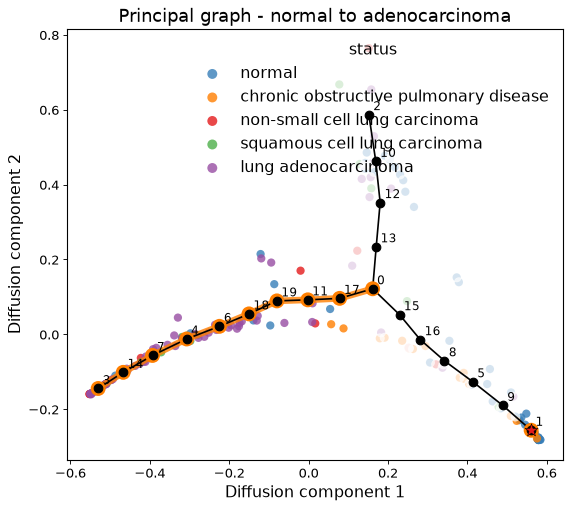

In [ ]:
pl.tl.select_branch(adata_lung, nodes = [1, 0, 17, 11, 19, 18, 6, 4, 7, 14, 3], name = 'normal to adenocarcinoma')
pl.pl.principal_graph(adata_lung)

In [ ]:
pl.tl.cell_importance_calculation(adata_lung)

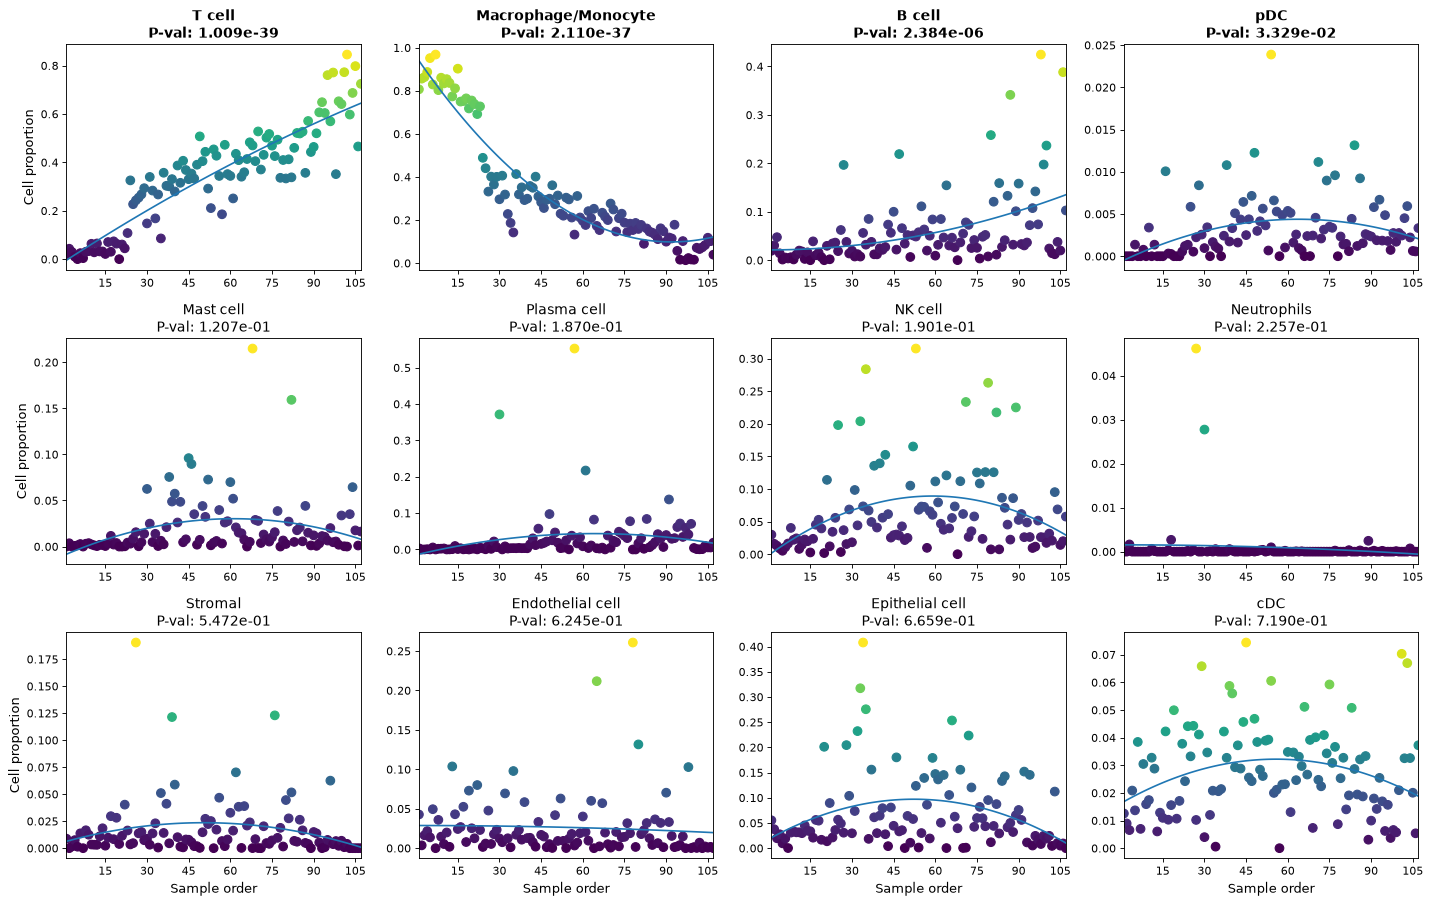

In [ ]:
pl.pl.cell_importance_grid(adata_lung)

In [ ]:
res_luad = pl.tl.correlation_with_trajectory(adata_lung)
res_luad.head(10)

Tested 16 variables (11 categorical, 5 numeric); skipped 35 columns.
  skipped (differs between the cells of a sample (cell-level)): ann_fine, cell_type_predicted, leiden, ann_coarse, cell_type_tumor, cell_type_major, cell_type_neutro, cell_type_neutro_coarse, ...
  skipped (only one value): doublet_status, platform, suspension_type, organism, tissue, organism_ontology_term_id, tissue_ontology_term_id
  skipped (same groups as 'assay'): assay_ontology_term_id
  skipped (same groups as 'disease'): accLabel, disease_ontology_term_id
  skipped (same groups as 'sex'): sex_ontology_term_id
  skipped (too many different values (107 for 107 samples, e.g. an ID)): sample, accSample
  skipped (too many different values (39 for 73 samples, e.g. an ID)): development_stage, development_stage_ontology_term_id
  skipped (too many missing values (107 of 107)): self_reported_ethnicity, self_reported_ethnicity_ontology_term_id
  skipped (too many missing values (96 of 107)): EGFR_mutation, TP53_mutatio

,Feature,Type,Level,Test,Statistic,P_value,Adjusted_P_value,Kruskal_P_value,N_samples,N_groups,Note
0,tumor_stage,categorical,sample,ANOVA,48.781292,1.245221e-15,1.545800e-14,6.876270e-12,106,3,
1,study,categorical,sample,ANOVA,16.783528,1.932250e-15,1.545800e-14,2.617695e-10,107,9,
2,dataset,categorical,sample (most frequent),ANOVA,11.871177,4.416711e-15,2.355579e-14,4.719579e-09,106,15,1 group(s) with < 2 samples not tested
3,origin,categorical,sample (most frequent),ANOVA,31.790541,1.252541e-14,5.010162e-14,4.984414e-11,107,4,
4,uicc_stage,categorical,sample,ANOVA,24.949905,2.214768e-14,7.087258e-14,1.070309e-10,106,5,
5,disease,categorical,sample,ANOVA,24.456651,3.309169e-14,8.824450e-14,1.452318e-10,107,5,
6,n_genes_by_counts,numeric,cell (mean),Spearman,-0.529713,4.441277e-09,1.015149e-08,NaN,107,107,
7,origin_fine,categorical,sample (most frequent),ANOVA,11.973986,2.332729e-08,4.665459e-08,1.298342e-06,75,6,
8,age,numeric,sample,Spearman,0.507435,4.608664e-06,8.193180e-06,NaN,73,39,
9,ever_smoker,categorical,sample,ANOVA,11.443066,1.043643e-03,1.669829e-03,1.112707e-03,97,2,


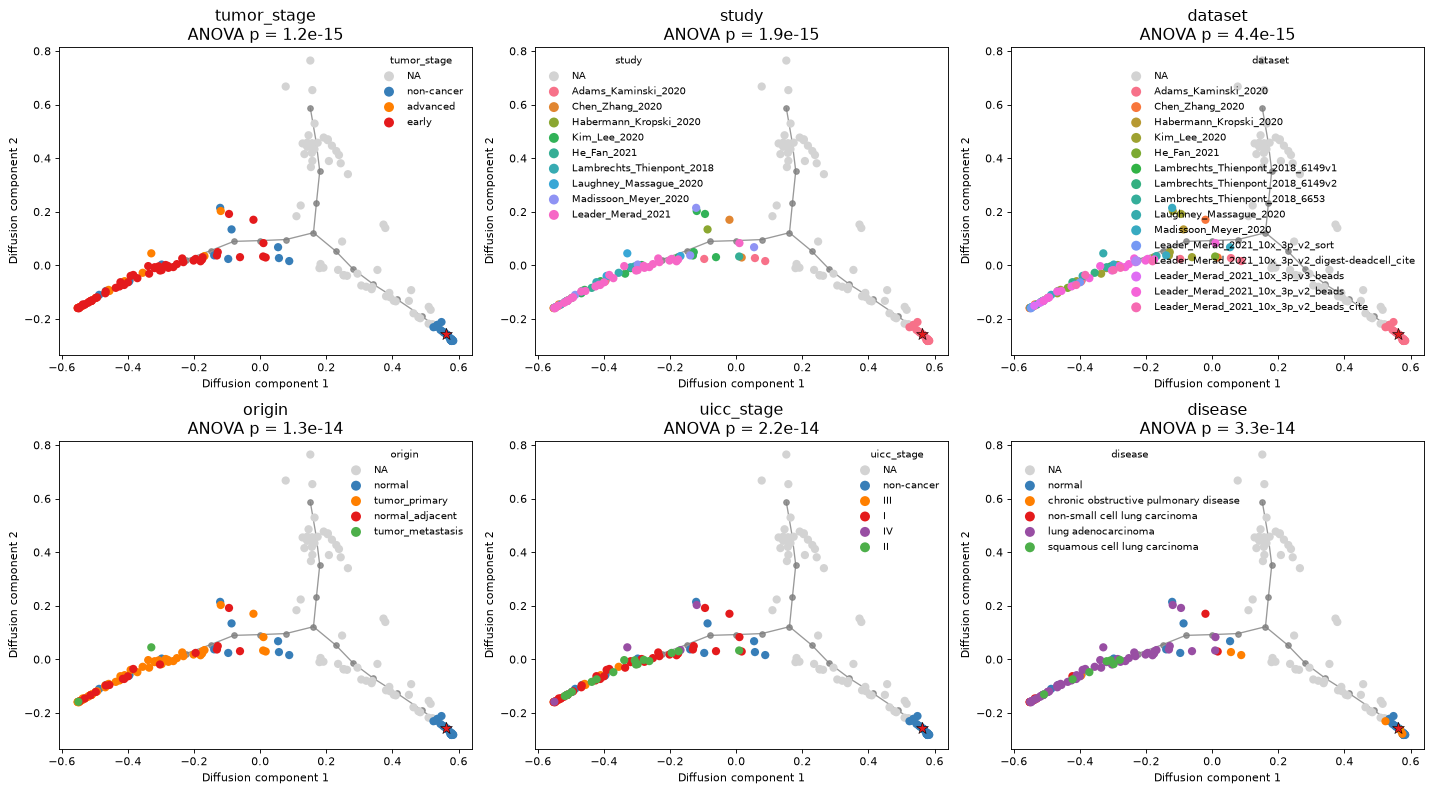

In [ ]:
pl.pl.trajectory_associations(adata_lung, top = 6)

Branch 'normal to COPD': 53 of 165 samples (normal: 31, chronic obstructive pulmonary disease: 14, lung adenocarcinoma: 4, squamous cell lung carcinoma: 2, non-small cell lung carcinoma: 2).
Branch 'normal to adenocarcinoma': 107 of 165 samples (lung adenocarcinoma: 57, normal: 28, non-small cell lung carcinoma: 9, squamous cell lung carcinoma: 7, chronic obstructive pulmonary disease: 6).

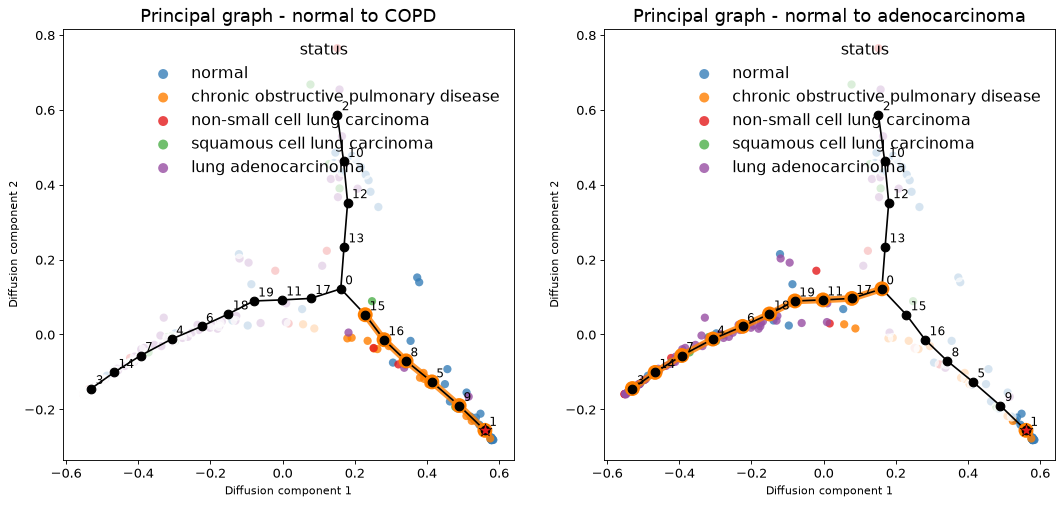

In [ ]:
fig, axes = plt.subplots(1, 2, figsize = (16, 7))
pl.tl.select_branch(adata_lung, nodes = [1, 9, 5, 8, 16, 15], name = 'normal to COPD')
pl.pl.principal_graph(adata_lung, ax = axes[0])
pl.tl.select_branch(adata_lung, nodes = [1, 0, 17, 11, 19, 18, 6, 4, 7, 14, 3], name = 'normal to adenocarcinoma')
pl.pl.principal_graph(adata_lung, ax = axes[1])
plt.show()

##### Summary of the lung example:
<div class="alert alert-block alert-info">
The lung trajectory has two disease branches that start from the normal samples: one towards COPD and one towards lung adenocarcinoma, with different cell types changing in each branch. The clinical variables show what else follows each branch. Here the study is strongly linked to the trajectory: the COPD branch comes almost only from one study, so part of its changes can be a batch effect. Always check the batch (e.g. with `pl.pl.trajectory_variable` or `pl.tl.correlation_with_trajectory`) before interpreting a branch.
</div>